# Regression Model

## 1. Loading and Preprocessing the Data

In [237]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [238]:
data = pd.read_csv("imdb_top_1000.csv")

In [239]:
X = data[['No_of_Votes']]
y = data['IMDB_Rating']
print(X) 
print(y) 

     No_of_Votes
0        2343110
1        1620367
2        2303232
3        1129952
4         689845
..           ...
995       166544
996        34075
997        43374
998        26471
999        51853

[1000 rows x 1 columns]
0      9.3
1      9.2
2      9.0
3      9.0
4      9.0
      ... 
995    7.6
996    7.6
997    7.6
998    7.6
999    7.6
Name: IMDB_Rating, Length: 1000, dtype: float64


## 2. Detecting and Removing Outliers

In [240]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = ~((X < lower_bound) | (X > upper_bound)).any(axis=1)

X = X[outlier_mask]
y = y[outlier_mask]

print("Outliers:", len(outlier_mask) - outlier_mask.sum())

Outliers: 67


## 3. Splitting the Data

In [241]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)
print(X_train)
print(X_test)
print(y_train)
print(y_test)

     No_of_Votes
606       179264
675       481918
497       107290
402       240266
898       411599
..           ...
834       181285
118       299198
975       195663
294        33044
75        787806

[746 rows x 1 columns]
     No_of_Votes
438        98431
835        47102
895        49397
314       290074
757       103330
..           ...
321        57428
235       334320
558        41625
640        50622
131       377884

[187 rows x 1 columns]
606    7.8
675    7.8
497    7.9
402    8.0
898    7.6
      ... 
834    7.7
118    8.3
975    7.6
294    8.1
75     8.4
Name: IMDB_Rating, Length: 746, dtype: float64
438    8.0
835    7.7
895    7.6
314    8.1
757    7.7
      ... 
321    8.1
235    8.1
558    7.9
640    7.8
131    8.2
Name: IMDB_Rating, Length: 187, dtype: float64


In [242]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## 4. Applying Regression Models & 5. Evaluating Models & 7. Printing the Regression Equation

### Linear Regression

In [243]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [244]:
y_pred = regressor.predict(X_test)
print(X_test)

[[-0.54601166]
 [-0.79732014]
 [-0.78608375]
 [ 0.39227883]
 [-0.52202599]
 [-0.86733342]
 [-0.73217353]
 [-0.49494114]
 [-0.48965832]
 [-0.80548673]
 [-0.66040258]
 [ 1.57659498]
 [-0.32604268]
 [ 0.79038997]
 [-0.18233921]
 [-0.7766442 ]
 [-0.8948834 ]
 [ 1.31785431]
 [-0.54530663]
 [-0.79450982]
 [-0.64132763]
 [ 0.49652027]
 [-0.83513221]
 [-0.10062442]
 [ 2.20228843]
 [-0.83453489]
 [-0.90093979]
 [-0.69596246]
 [-0.03317177]
 [-0.68341393]
 [ 0.18464785]
 [ 1.12561647]
 [-0.81402541]
 [-0.56986023]
 [-0.74167183]
 [-0.84470395]
 [ 0.37596525]
 [-0.27947161]
 [ 2.1612254 ]
 [-0.87147057]
 [-0.67119343]
 [-0.48323962]
 [ 1.930304  ]
 [-0.57599986]
 [ 0.39807083]
 [ 1.16239547]
 [-0.80760181]
 [-0.88593345]
 [ 0.08718742]
 [-0.29152564]
 [ 0.01321325]
 [-0.095087  ]
 [-0.77706036]
 [-0.71674123]
 [ 1.05511849]
 [ 0.16880429]
 [-0.58316765]
 [ 0.6522435 ]
 [-0.09402456]
 [-0.86463081]
 [-0.15286019]
 [-0.77411784]
 [-0.89539258]
 [ 1.67848633]
 [-0.47150382]
 [-0.6658029 ]
 [ 2.10358

In [245]:
print(regressor.coef_)
print(regressor.intercept_)

[0.03245822]
7.918900804289544


In [246]:
from sklearn.metrics import r2_score
print(r2_score(y_test, y_pred))

0.0599691176371695


In [247]:
from sklearn.metrics import mean_squared_error

mse_linear = mean_squared_error(y_test, y_pred)
print(mse_linear)

0.0574072335646178


### Polynomial Regression

In [248]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
poly_reg = PolynomialFeatures(degree = 2)
X_train_poly = poly_reg.fit_transform(X_train)
X_test_poly = poly_reg.transform(X_test)
regressor = LinearRegression()
regressor.fit(X_train_poly, y_train)

LinearRegression()

In [249]:
y_pred_poly = regressor.predict(X_test_poly)

In [250]:
from sklearn.metrics import r2_score
r2_score(y_test, regressor.predict(poly_reg.transform(X_test)))

0.09827713347218725

In [251]:
from sklearn.metrics import mean_squared_error
mse_poly = mean_squared_error(y_test, y_pred_poly)
print(mse_poly)

0.05506778147458623


In [252]:
print(regressor.coef_)
print(regressor.intercept_)

[ 0.         -0.00571923  0.03068615]
7.888214655054095


### Ridge Regression

In [253]:
from sklearn.linear_model import Ridge
rdge=Ridge(alpha=0.1)
rdge.fit(X_train,y_train)
y_pred_test=rdge.predict(X_test)
print(r2_score(y_test,y_pred_test))

0.059962432343713234


In [254]:
y_pred_ridge = rdge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(mse_ridge)

0.05740764183227164


In [255]:
y_pred_ridge = rdge.predict(X_test)

### Lasso Regression

In [256]:
from sklearn.linear_model import Lasso
las=Lasso(alpha=0.1)
las.fit(X_train,y_train)
y_pred_test=las.predict(X_test)
print(r2_score(y_test,y_pred_test))

-0.005849733390721479


In [257]:
y_pred_lasso = las.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
print(mse_lasso)

0.061426759119369206


In [258]:
y_pred_lasso = las.predict(X_test)

### Elastic Net Regression

In [259]:
from sklearn.linear_model import ElasticNet
enet=ElasticNet(alpha=0.1)
enet.fit(X_train,y_train)
y_pred_test=enet.predict(X_test)
print(r2_score(y_test,y_pred_test))

-0.005849733390721479


In [260]:
y_pred_enet = enet.predict(X_test)
mse_enet = mean_squared_error(y_test, y_pred_enet)
print(mse_enet)

0.061426759119369206


In [261]:
y_pred_enet = enet.predict(X_test)

## 6. Selecting the Best Model

In [262]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression', 'Elastic Net Regression'],
    'MSE': [mse_linear, mse_poly, mse_ridge, mse_lasso, mse_enet],
    'R² Score': [
        r2_score(y_test, y_pred),  
        r2_score(y_test, y_pred_poly),  
        r2_score(y_test, y_pred_ridge),  
        r2_score(y_test, y_pred_lasso), 
        r2_score(y_test, y_pred_enet)  
    ]
})

print("Model Comparison Table:")
print(model_comparison.to_string(index=False))

Model Comparison Table:
                 Model      MSE  R² Score
     Linear Regression 0.057407  0.059969
 Polynomial Regression 0.055068  0.098277
      Ridge Regression 0.057408  0.059962
      Lasso Regression 0.061427 -0.005850
Elastic Net Regression 0.061427 -0.005850


In [263]:
best_model_row = model_comparison.loc[model_comparison['R² Score'].idxmax()]
print("\nBest-Fit Model:")
print(f"Model: {best_model_row['Model']}")
print(f"R2 Score: {best_model_row['R² Score']}")
print(f"MSE: {best_model_row['MSE']}")


Best-Fit Model:
Model: Polynomial Regression
R2 Score: 0.09827713347218725
MSE: 0.05506778147458623


## 8. Visualization

### Linear Regression Visualization

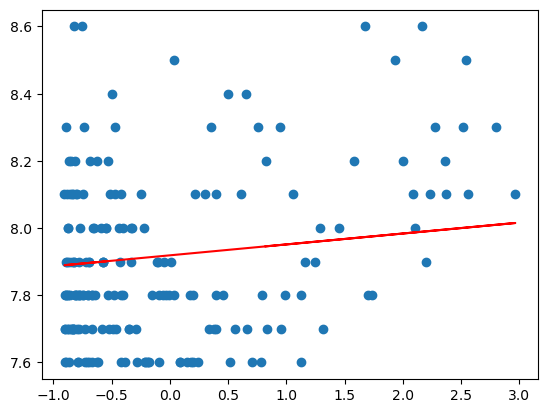

In [264]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, color='red')
plt.show()

### Polynomial Regression Visualization

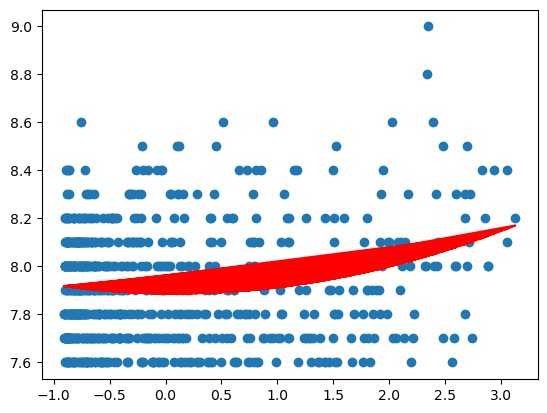

In [265]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regressor.predict(poly_reg.transform(X_train)), color='red')
plt.show()

### Ridge Regression Visualization

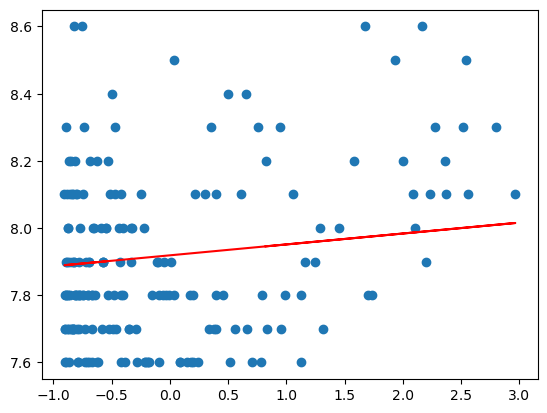

In [266]:
plt.scatter(X_test, y_test)
plt.plot(X_test, rdge.predict(X_test), color='red')
plt.show()

### Lasso Regression Visualization

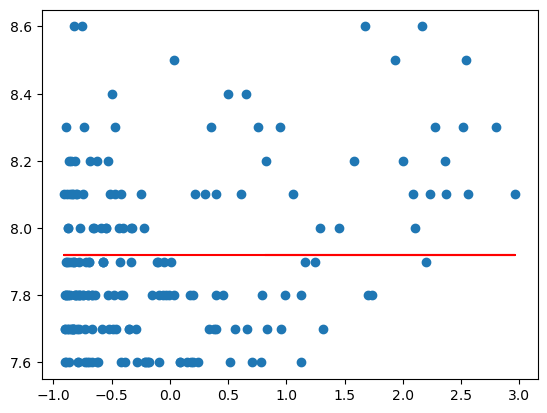

In [267]:
plt.scatter(X_test, y_test)
plt.plot(X_test, las.predict(X_test), color='red')
plt.show()

### Elastic Net Regression Visualization

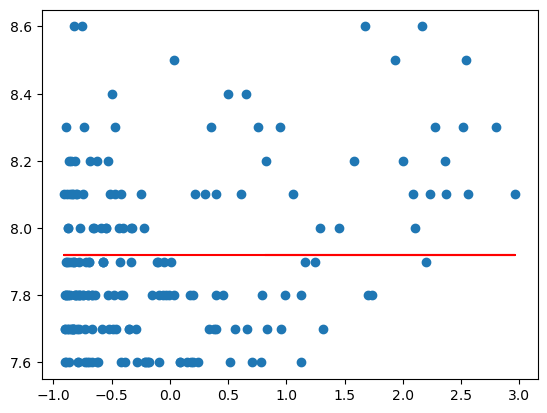

In [268]:
plt.scatter(X_test, y_test)
plt.plot(X_test, enet.predict(X_test), color='red')
plt.show()

# Classification Model

In [269]:
threshold = np.median(y_train)
y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

print({threshold})

{np.float64(7.9)}


In [270]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

eval_results = []

for name, clf in classifiers.items():
    y_pred_cv = cross_val_predict(clf, X_train, y_train_class, cv=5)
    
    cm = confusion_matrix(y_train_class, y_pred_cv)
    acc = accuracy_score(y_train_class, y_pred_cv)
    prec = precision_score(y_train_class, y_pred_cv, zero_division=0)
    rec = recall_score(y_train_class, y_pred_cv, zero_division=0)
    f1 = f1_score(y_train_class, y_pred_cv, zero_division=0)
    
    errors = int(cm[0, 1] + cm[1, 0])
    
    cm_str = f"[[{cm[0,0]} {cm[0,1]}]\n [ {cm[1,0]} {cm[1,1]}]]"
    
    eval_results.append({
        'Model': name,
        'Confusion Matrix': cm_str,
        'Errors (FP + FN)': errors,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

model_comparison_class = pd.DataFrame(eval_results)

print("Cross-Validation Classification Model Results:")
print(model_comparison_class.to_string(index=False))

best_clf_row = model_comparison_class.loc[model_comparison_class['F1-Score'].idxmax()]
print("\nBest-Fit Model:")
print(f"Model: {best_clf_row['Model']}")
print(f"Accuracy:  {best_clf_row['Accuracy']}")
print(f"Precision: {best_clf_row['Precision']}")
print(f"Recall:    {best_clf_row['Recall']}")
print(f"F1-Score:  {best_clf_row['F1-Score']}")

Cross-Validation Classification Model Results:
                 Model         Confusion Matrix  Errors (FP + FN)  Accuracy  Precision   Recall  F1-Score
   Logistic Regression   [[364 49]\n [ 278 55]]               327  0.561662   0.528846 0.165165  0.251716
   K-Nearest Neighbors [[262 151]\n [ 199 134]]               350  0.530831   0.470175 0.402402  0.433657
           Naive Bayes   [[351 62]\n [ 265 68]]               327  0.561662   0.523077 0.204204  0.293737
Support Vector Machine   [[401 12]\n [ 299 34]]               311  0.583110   0.739130 0.102102  0.179420
         Decision Tree [[241 172]\n [ 167 166]]               339  0.545576   0.491124 0.498498  0.494784
         Random Forest [[241 172]\n [ 167 166]]               339  0.545576   0.491124 0.498498  0.494784

Best-Fit Model:
Model: Decision Tree
Accuracy:  0.5455764075067024
Precision: 0.4911242603550296
Recall:    0.4984984984984985
F1-Score:  0.4947839046199702


In [271]:
best_model_name = model_comparison_class.loc[model_comparison_class['F1-Score'].idxmax(), 'Model']

from sklearn.model_selection import cross_val_predict
best_clf = classifiers[best_model_name]
y_pred_best = cross_val_predict(best_clf, X_train, y_train_class, cv=5)

category_counts = pd.Series(y_pred_best).value_counts().sort_index()

print(f"Best-Fit Classifier: {best_model_name}")
print("Number of elements in each category:")
for cat, count in category_counts.items():
    print(f"Category {cat}: {count} elements")

Best-Fit Classifier: Decision Tree
Number of elements in each category:
Category 0: 408 elements
Category 1: 338 elements


# Cluster Analysis

## K-means Clustering

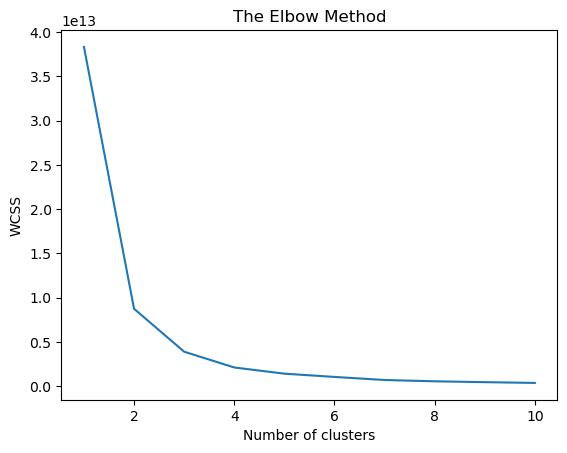

In [272]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [273]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)
print(y_kmeans)

[1 1 0 1 0 1 1 1 0 2 2 1 1 1 2 2 2 1 1 2 0 0 0 0 2 0 2 1 1 2 2 0 2 1 2 2 1
 1 0 0 2 0 0 2 2 2 2 0 0 0 2 2 0 0 0 1 1 1 0 1 0 1 2 1 2 1 2 1 1 2 2 0 2 2
 2 0 0 0 2 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 2 2 0 1 1 1 0 0 0 2 2 1 0 1
 1 0 1 1 0 2 1 0 2 1 0 2 0 0 0 0 1 2 2 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 2 0 0 0 0 0 1 0 2 1 0 1 2 2 2 0 0 0 1 0 1 1 0 2 0 1 1 0 1 2 0 2 0
 0 0 1 2 1 0 0 0 0 1 0 1 1 0 0 0 2 0 0 0 0 0 2 2 2 0 0 2 0 0 0 1 2 2 2 1 0
 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 2 0 0 0 0 0 0 0 0 0 2 0 0 0
 0 0 0 0 0 0 0 0 0 1 2 1 2 0 0 0 0 0 0 0 1 1 1 2 1 1 0 1 2 0 0 2 0 0 1 1 0
 0 2 2 1 1 0 1 0 0 1 1 1 0 0 0 0 0 0 2 1 0 0 0 1 2 0 0 0 0 0 0 0 0 0 1 0 2
 1 0 2 2 0 2 2 0 1 0 2 0 0 0 1 2 0 0 2 1 2 0 0 2 0 0 0 0 2 2 0 2 0 2 0 2 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 2 2 0 0
 0 0 0 1 1 2 1 0 1 0 2 1 0 2 0 2 2 1 2 0 2 0 1 2 0 0 0 1 2 0 0 1 0 2 1 0 0
 0 0 1 0 1 2 2 1 2 0 0 2 0 0 2 2 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

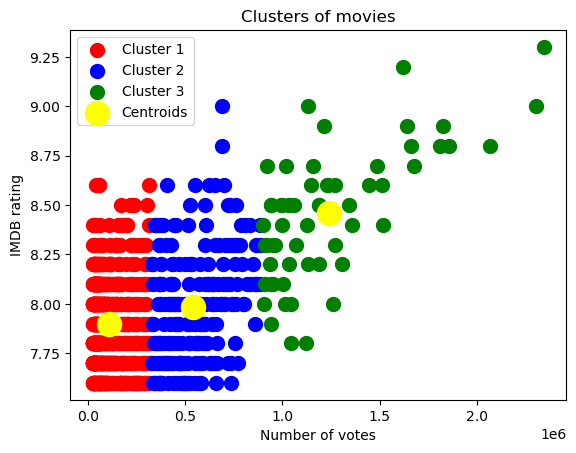

In [274]:
X = data[['No_of_Votes', 'IMDB_Rating']].to_numpy()
y_kmeans = kmeans.fit_predict(X)

plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=100, c='red', label='Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=100, c='blue', label='Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=100, c='green', label='Cluster 3')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids')
plt.title('Clusters of movies')
plt.xlabel('Number of votes')
plt.ylabel('IMDB rating')
plt.legend()
plt.show()

## Heirarchal Clustering

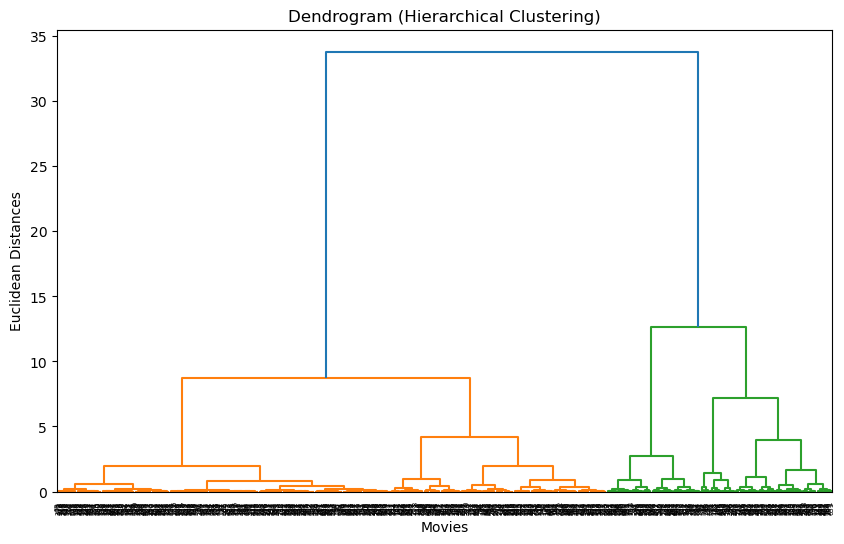

In [275]:
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_train, method='ward'))
plt.title('Dendrogram (Hierarchical Clustering)')
plt.xlabel('Movies')
plt.ylabel('Euclidean Distances')
plt.show()

In [276]:
from sklearn.cluster import AgglomerativeClustering
X = data[['No_of_Votes', 'IMDB_Rating']].to_numpy()

hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

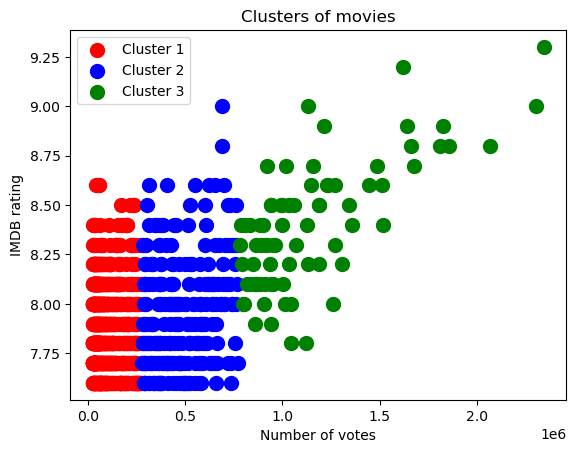

In [277]:
cluster_means = [(i, np.mean(X[y_hc == i, 0])) for i in np.unique(y_hc)]
cluster_means_sorted = sorted(cluster_means, key=lambda x: x[1])
label_mapping = {old_label: new_label for new_label, (old_label, _) in enumerate(cluster_means_sorted)}
y_hc = np.array([label_mapping[label] for label in y_hc])

plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.title('Clusters of movies')
plt.xlabel('Number of votes')
plt.ylabel('IMDB rating')
plt.legend()
plt.show()